# Задание 1 

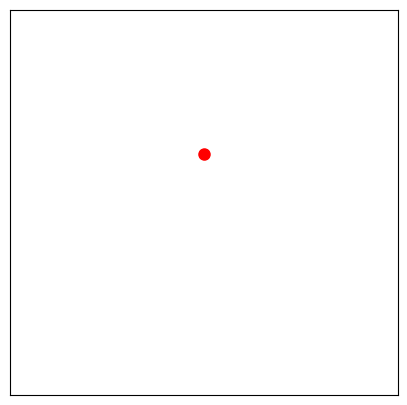

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

t = np.linspace(0, 2 * np.pi, 250)
x = (16 * (np.sin(t))**3)
y = (13 * np.cos(t) - 5 * np.cos(2*t) - 2 * np.cos(3*t) - np.cos(4*t))

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_xticks([])
ax.set_yticks([])


(line,) = ax.plot([], [], "r-", lw=2)
(dot,) = ax.plot([], [], "ro", ms=8)


def update(frame):
    n = frame + 1
    line.set_data(x[:n], y[:n])  # ← срез
    dot.set_data([x[n - 1]], [y[n - 1]])
    return line, dot


ani = FuncAnimation(fig, update, frames=len(x), interval=30)
HTML(ani.to_jshtml())

# Задание 2

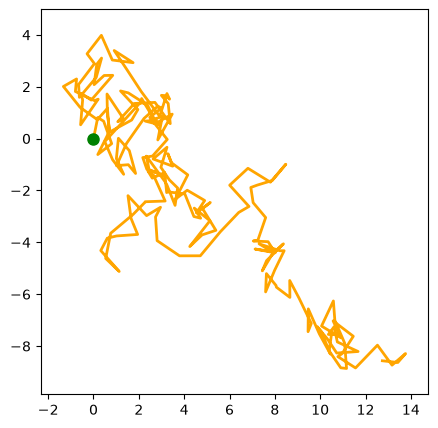

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

xs, ys = [0], [0]
fig, ax = plt.subplots(figsize=(5, 5))

(line,) = ax.plot([], [], "-", color="orange" ,lw=2)
(dot,) = ax.plot([], [],  marker="o",linestyle="None", color="green", ms=8)


def update(frame):
    n = frame + 1
    xs.append(xs[-1] + np.random.uniform(-1, 1))
    ys.append(ys[-1] + np.random.uniform(-1, 1))
    line.set_data(xs, ys)
    dot.set_data([xs[n - 1]], [ys[n - 1]])
    ax.set_xlim(min(xs) - 1, max(xs) + 1)   # авто-масштаб
    ax.set_ylim(min(ys) - 1, max(ys) + 1)
    return line, dot



ani = FuncAnimation(fig, update, frames=200, interval=50)
HTML(ani.to_jshtml())

# Задание 3

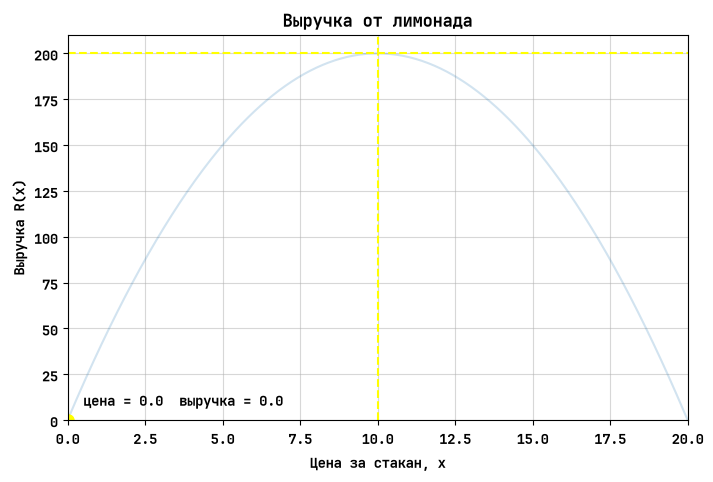

In [87]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

x = np.linspace(0, 20, 400)
R = (-2*x**2 + 40*x)
its_peak = int(np.argmax(R))

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlim(0, 20)
ax.set_ylim(0, 210)
ax.set_xlabel("Цена за стакан, x")
ax.set_ylabel("Выручка R(x)")
ax.set_title("Выручка от лимонада")
ax.grid(True, linestyle="-", alpha=0.5)
ax.plot(x,R, alpha=0.2)


(line,) = ax.plot([], [], "r-", lw=2)
(dot,) = ax.plot([], [], "ro", ms=8)

info_text = ax.text(
    0.5,
    7.8,
    "")

def update(frame):
    n = frame + 1
    if n == its_peak+1:
        line.set_data(x[:n], R[:n])  # ← срез
        dot.set_data([x[n - 1]], [R[n - 1]])
        
        ax.axhline(R[its_peak], color="yellow", linestyle="--", lw=1.5)
        ax.axvline(x[its_peak], color="yellow", linestyle="--", lw=1.5)
               
        info_text.set_text(f"цена = {round(x[n - 1], 1)}  выручка = {round(R[n - 1], 1)}")
        dot.set_color("yellow")
        
        return line, dot, info_text
    
    info_text.set_text(f"цена = {round(x[n - 1], 1)}  выручка = {round(R[n - 1], 1)}")
    line.set_data(x[:n], R[:n])  # ← срез
    dot.set_data([x[n - 1]], [R[n - 1]])
    return line, dot, info_text


ani = FuncAnimation(fig, update, frames=its_peak+1, interval=30)
HTML(ani.to_jshtml())

# 4 задание

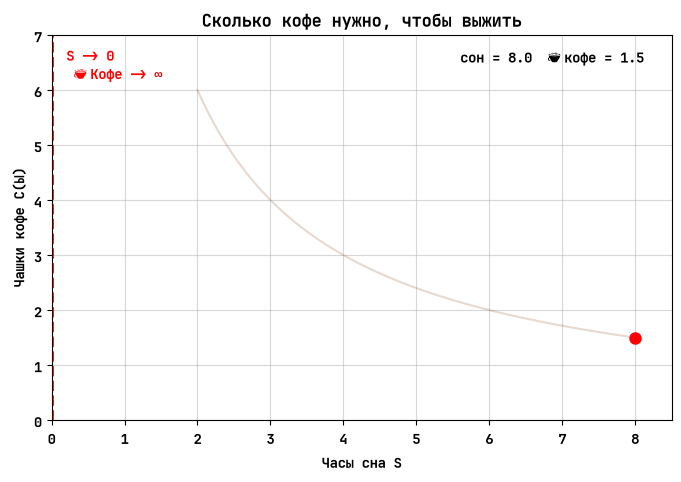

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

plt.rcParams["font.family"] = "JetBrainsMono Nerd Font"
S = np.linspace(2, 8, 400)
S_anim = np.linspace(8,2, 400)
C = 12 / S
C_anim = 12 / S_anim


fig, ax = plt.subplots(figsize=(8, 5))

ax.set_xlim(0, 8.5)
ax.set_ylim(0, 7)
ax.set_xlabel("Часы сна S")
ax.set_ylabel("Чашки кофе С(Ы)")
ax.set_title("Сколько кофе нужно, чтобы выжить")
ax.grid(True, linestyle="-", alpha=0.5)
ax.plot(S,C, alpha=0.2, color="saddlebrown")
ax.axvline(0, ls='--', color='red', lw=2)

fiftcent = len(S) * 65 / 100
seven_eleven = len(S) * 95 / 100


(line,) = ax.plot([], [], linestyle="-", color="saddlebrown", lw=2)
(dot,) = ax.plot([], [], marker="o", color ="green", ms=8)

info_text = ax.text(
    5.6,
    6.5,
    ""
)

lim_text = ax.text(
    0.2,
    6.2,
    "S -> 0\n  Кофе -> ∞",
    color="red"
)

def update(frame):
    n = frame + 1
    if n-1 >= fiftcent and n-1 < seven_eleven:
        info_text.set_text(f"сон = {round(S_anim[n - 1], 1)}   кофе = {round(C_anim[n - 1], 1)}")
        line.set_data(S_anim[:n], C_anim[:n])  # ← срез
        dot.set_data([S_anim[n - 1]], [C_anim[n - 1]])
        dot.set_color("yellow")
        return line, dot, info_text
    elif n-1 >= seven_eleven:
        info_text.set_text(f"сон = {round(S_anim[n - 1], 1)}   кофе = {round(C_anim[n - 1], 1)}")
        line.set_data(S_anim[:n], C_anim[:n])  # ← срез
        dot.set_data([S_anim[n - 1]], [C_anim[n - 1]])
        dot.set_color("red")
        return line, dot, info_text
    else:      
        info_text.set_text(f"сон = {round(S_anim[n - 1], 1)}   кофе = {round(C_anim[n - 1], 1)}")
        line.set_data(S_anim[:n], C_anim[:n])  # ← срез
        dot.set_data([S_anim[n - 1]], [C_anim[n - 1]])
        return line, dot, info_text


ani = FuncAnimation(fig, update, frames=len(S), interval=30)
HTML(ani.to_jshtml())

# 5 Задание


In [30]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

plt.rcParams["font.family"] = "JetBrainsMono Nerd Font"
t_stop = 20 * np.log2(1000)
t = np.linspace(0, t_stop, 250)  # Поставь 400 после теста
N = 2 ** (t / 20)

fig, (boom, ax) = plt.subplots(1, 2, figsize=(12, 4.5))

boom.set_xlim(0, t_stop * 1.05)
boom.set_ylim(0, 1150)
boom.set_xlabel("Минуты")
boom.set_ylabel("Бактерий")
boom.set_title("Обычная шкала: «незаметно → БУМ!»")
boom.grid(True, linestyle="-", alpha=0.5)
boom.axhline(1000, ls="--", color="red", alpha=0.8)
boom.plot(t, N, alpha=0.2, color="green")

ax.set_xlim(0, t_stop * 1.05)
ax.set_ylim(1, 1500)  # 0 для лог нельзя!
ax.set_yscale("log")
ax.set_xlabel("Минуты")
ax.set_ylabel("Бактерий (log)")
ax.set_title("Лог-шкала: ровная прямая")
ax.grid(True, which="both", linestyle="-", alpha=0.3)
ax.plot(t, N, alpha=0.2, color="green")
ax.axhline(1000, ls="--", color="red", alpha=0.8)

(line_boom,) = boom.plot([], [], linestyle="-", color="green", lw=2)
(dot_boom,) = boom.plot([], [], marker="o", color="green", ms=8)

(line,) = ax.plot([], [], linestyle="-", color="green", lw=2)
(dot,) = ax.plot([], [], marker="o", color="green", ms=8)

info_text = boom.text(10, 1000, "")
info_text_v2 = ax.text(10, 500, "")

last_frame = len(t) - 1


def update(frame):
    n = frame + 1

    line_boom.set_data(t[:n], N[:n])
    dot_boom.set_data([t[n - 1]], [N[n - 1]])

    line.set_data(t[:n], N[:n])
    dot.set_data([t[n - 1]], [N[n - 1]])

    info_text.set_text(f"t = {t[n - 1]:.1f} мин\nN = {N[n - 1]:.0f}")
    info_text_v2.set_text(f"t = {t[n - 1]:.1f} мин\nN = {N[n - 1]:.0f}")

    if frame == last_frame:
        dot_boom.set_color("red")
        dot_boom.set_markersize(12)
        dot.set_color("red")
        dot.set_markersize(12)

        hours = int(t_stop // 60)
        mins = t_stop % 60
        boom.set_title(
            f"1000 бактерий достигнуто за {t_stop:.1f} мин ({hours} ч {mins:.1f} мин)!",
        )
        ax.set_title(
            f"1000 бактерий достигнуто за {t_stop:.1f} мин ({hours} ч {mins:.1f} мин)!",
        )

    return line_boom, dot_boom, line, dot, info_text


plt.tight_layout()
ani = FuncAnimation(fig, update, frames=len(t), interval=30, repeat=False)
plt.close(fig)
HTML(ani.to_jshtml())

# 6 Задание

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

plt.rcParams["font.family"] = "JetBrainsMono Nerd Font"
t = np.linspace(0, t_stop, 800)  # Поставь 400 после теста
T = 20 + 70 * np.e**(-0.05*t)

fig, ax = plt.subplots(figsize=(8, 5))

ax.set_xlim(0, 25 * 1.05)
ax.set_ylim(1, 95)
ax.set_yticks(np.arange(0,100,10))
ax.set_xlabel("Минуты")
ax.set_ylabel("Температура °C")
ax.set_title("Чай остывает по закону Ньютона")
ax.grid(True, which="both", linestyle="-", alpha=0.3)
ax.plot(t, T, alpha=0.2, color="red")
ax.axhline(40, ls="--", color="gold", alpha=0.8)
ax.axhline(20, ls="--", color="blue", alpha=0.8)

(line,) = ax.plot([], [], linestyle="-", color="red", lw=2)
(dot,) = ax.plot([], [], marker="o", color="red", ms=8)

info_text = ax.text(20, 80, "")
ax.text(1,42, "Питьевая 40°C", color="gold")
ax.text(14,22, "Комнатная 20°C", color="blue")

it_is_time = int(np.argmin(np.abs(T - 40)))

def update(frame):
    n = frame + 1
    
    temp_now = T[n-1]
    minut = t[n-1]
    
    info_text.set_text(f"t = {round(minut,1)} min \n T = {round(temp_now,1)} °C")
    line.set_data(t[:n], T[:n])
    dot.set_data([t[n - 1]], [T[n - 1]])
    if n-1 == it_is_time:
        dot.set_color("gold")
            
    return line, dot, info_text


plt.tight_layout()
ani = FuncAnimation(fig, update, frames=it_is_time+1, interval=30, repeat=False)
plt.close(fig)
HTML(ani.to_jshtml())